### Dataset Import

In [6]:
!pip install plotly

   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.7 MB 1.9 MB/s eta 0:00:05
   ---- ----------------------------------- 1.0/9.7 MB 1.9 MB/s eta 0:00:05
   ------- -------------------------------- 1.8/9.7 MB 2.1 MB/s eta 0:00:04
   --------- ------------------------------ 2.4/9.7 MB 2.3 MB/s eta 0:00:04
   ----------- ---------------------------- 2.9/9.7 MB 2.4 MB/s eta 0:00:03
   -------------- ------------------------- 3.4/9.7 MB 2.4 MB/s eta 0:00:03
   ---------------- ----------------------- 3.9/9.7 MB 2.4 MB/s eta 0:00:03
   ------------------- -------------------- 4.7/9.7 MB 2.4 MB/s eta 0:00:03
   --------------------- ------------------ 5.2/9.7 MB 2.5 MB/s eta 0:00:02
   ------------------------- -------------- 6.3/9.7 MB 2.7 MB/s eta 0:00:02
   ----------------------------- 


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import  plotly.graph_objects as go

In [10]:
data = pd.read_csv("Dataset/gurgaon-properties-missingValue-removed.csv")
data.head(10)

,property_name,property_type,society,sector,area,price,price_per_sqft,Plot area,Super Built Up area,Built Up area,...,TV,Washing Machine,Bed,AC,Light,Fan,Exhaust Fan,Modular Kitchen,furnishing_type,luxury score
0,3 BHK Flat in Sector-33 Sohna,flat,Central Park Flower Valley Aqua Front Towers,Sector-33 Sohna,1789.10,1.700,9502.0,0.00,1788.96,1781.139,...,0,0,0,2,1,1,0,0,0,33
1,3 BHK Flat in Sector 84 Gurgaon,flat,Antriksh Heights,Sector 84 Gurgaon,1350.00,0.945,7000.0,0.00,1350.01,1344.108,...,0,0,0,0,20,6,1,1,2,98
2,5 Bedroom House for sale in Jacobpura,house,Jacobpura,Jacobpura,2002.09,1.700,8000.0,0.00,0.00,2000.040,...,0,0,0,0,0,0,0,0,0,9
3,3 BHK Flat in Sector 77 Gurgaon,flat,Emaar Palm Premier,Sector 77 Gurgaon,2000.00,2.100,10500.0,0.00,2000.04,1599.950,...,0,0,0,0,10,0,1,1,2,138
4,2 BHK Flat in Sector 65 Gurgaon,flat,M3M Heights,Sector 65 Gurgaon,1261.03,2.100,16653.0,0.00,1260.99,1117.577,...,0,0,0,4,6,6,0,0,0,40
5,2 BHK Flat in Sector 79 Gurgaon,flat,Supertech Basera,Sector 79 Gurgaon,471.02,0.360,7643.0,0.00,0.00,546.050,...,0,0,0,0,0,0,0,0,0,69
6,3 BHK Flat in Sector 107 Gurgaon,flat,M3M Woodshire,Sector 107 Gurgaon,1202.03,1.300,10815.0,0.00,1942.99,1703.257,...,0,0,0,0,0,0,0,0,0,98
7,6 Bedroom House for sale in Saraswati Vihar,house,Housing Board Colony,Saraswati Vihar,1345.49,3.500,25926.0,1350.01,0.00,1345.490,...,0,0,0,0,0,0,0,0,0,0
8,"2 Bedroom House for sale in Mahalaxmi Garden, ...",house,"Mahalaxmi Garden, Rajendra Place","Mahalaxmi Garden, Rajendra Place",452.08,0.380,8444.0,450.04,0.00,452.080,...,0,0,0,0,0,0,0,0,0,0
9,1 Bedroom House for sale in Mianwali Colony,house,Project Mianwali Colony,Mianwali Colony,1797.57,1.700,9444.0,0.00,0.00,2204.416,...,0,0,0,0,0,0,0,0,0,0


dropping  
1.           price per sqft because if user knows this val then it can find total price also 
2.           society name , bacause for specific society he can just go and look for that 
    Therefore,unnecessary col

In [21]:
data.drop(columns=['society','price_per_sqft','Plot area','Super Built Up area','Carpet area','area','Dining Table', 'Curtains',
       'Sofa', 'Water Purifier', 'Chimney', 'Geyser', 'Wardrobe', 'Fridge',
       'Microwave', 'Stove', 'TV', 'Washing Machine', 'Bed', 'AC', 'Light',
       'Fan', 'Exhaust Fan', 'Modular Kitchen','description','rating','facing'],inplace=True,errors='ignore')
data.shape

(934, 18)

In [22]:
data.columns

Index(['property_name', 'property_type', 'sector', 'price', 'Built Up area',
       'bedRoom', 'bathroom', 'balcony', 'address', 'floorNum',
       'agePossession', 'Study Room', 'Pooja Room', 'Servant Room',
       'Store Room', 'Others', 'furnishing_type', 'luxury score'],
      dtype='object')

In [23]:
dt = data.copy()

### luxury score
since i can not ask luxury score about customer , this feature is created by us - therefore let us divide it into  category - budget ,semi-budget,luxurious

<Axes: xlabel='luxury score'>

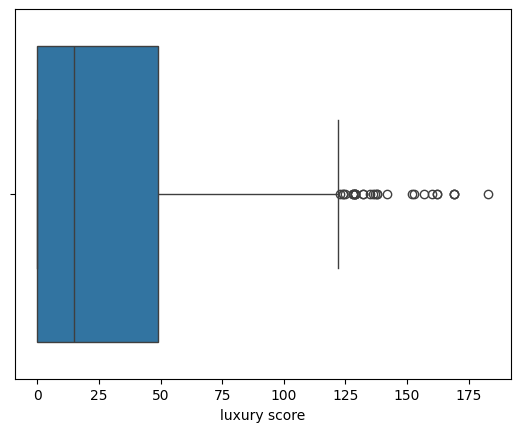

In [25]:
sns.boxplot(x=dt['luxury score'])

<Axes: xlabel='luxury score', ylabel='price'>

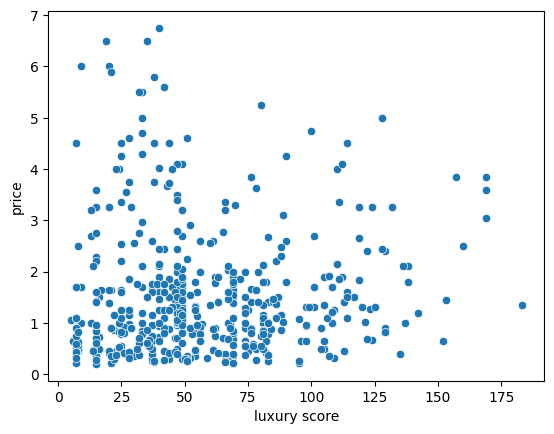

In [29]:
x = dt[(dt['price']<8) & (dt['luxury score']!=0)]
sns.scatterplot(x,x='luxury score',y ='price')